# 04 · Logistic Regression

The readable baseline model: its coefficients become **odds ratios** that explain *why* a client is likely to subscribe.

- Imbalance handled with `class_weight='balanced'` (lesson 11, option 3)
- Regularisation strength `C` tuned with `GridSearchCV` over `StratifiedKFold` (lessons 12, 13), scored on ROC-AUC

In [1]:
import sys, json
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from prep import load_data, split, linear_preprocessor, tree_preprocessor, evaluate, save_result, RANDOM_STATE

sns.set_theme(style='whitegrid')
df = load_data()
X_train, X_test, y_train, y_test = split(df)
print('train', X_train.shape, f'yes rate {y_train.mean():.1%}')
print('test ', X_test.shape, f'yes rate {y_test.mean():.1%}')

train (36168, 18) yes rate 11.7%
test  (9043, 18) yes rate 11.7%


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

pipe = Pipeline([
    ('prep', linear_preprocessor()),
    ('model', LogisticRegression(class_weight='balanced', max_iter=2000)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(pipe, {'model__C': [0.01, 0.1, 1, 10]}, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

print('best C:', grid.best_params_['model__C'], '| CV ROC-AUC:', round(grid.best_score_, 4))
pd.DataFrame(grid.cv_results_)[['param_model__C', 'mean_test_score', 'std_test_score']].round(4)

best C: 0.1 | CV ROC-AUC: 0.772


,param_model__C,mean_test_score,std_test_score
0,0.01,0.7698,0.0028
1,0.10,0.7720,0.0038
2,1.00,0.7719,0.0041
3,10.00,0.7718,0.0040


## 1. Test-set evaluation (threshold 0.5)

In [3]:
lr = grid.best_estimator_
proba_lr = lr.predict_proba(X_test)[:, 1]
save_result(evaluate('Logistic Regression', y_test, proba_lr))

,model,threshold,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Baseline (always no),0.5,0.8830,0.500,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.5,0.7734,0.713,0.2876,0.6342,0.3958,0.7789


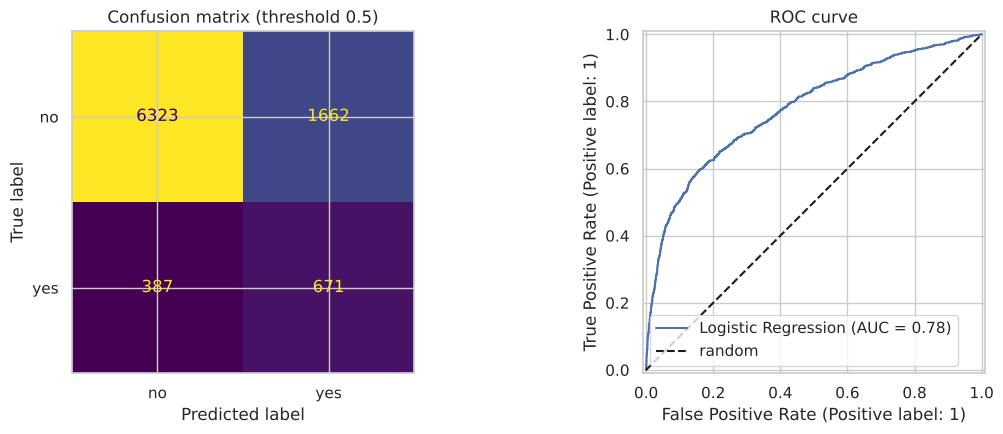

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, (proba_lr >= 0.5).astype(int),
                                        display_labels=['no', 'yes'], ax=axes[0], colorbar=False)
axes[0].set_title('Confusion matrix (threshold 0.5)')
RocCurveDisplay.from_predictions(y_test, proba_lr, ax=axes[1], name='Logistic Regression')
axes[1].plot([0, 1], [0, 1], 'k--', label='random')
axes[1].set_title('ROC curve'); axes[1].legend()
plt.tight_layout(); plt.show()

With class weights the model finds about **63%** of subscribers, but only about **29%** of the clients it flags actually subscribe.
That trade-off is set by the threshold, which is tuned in notebook 07.

## 2. Odds ratios: what drives subscription?

Numeric features were scaled, so their odds ratio is per one standard deviation. One-hot features are compared with the dropped reference category
(job = admin., marital = divorced, education = primary, contact = cellular, month = apr, poutcome = failure, age 18–25, previous 0, pdays 1–90).

In [5]:
names = lr.named_steps['prep'].get_feature_names_out()
coefs = lr.named_steps['model'].coef_[0]
odds = (pd.DataFrame({'feature': names, 'coef': coefs, 'odds_ratio': np.exp(coefs)})
        .sort_values('coef', ascending=False).reset_index(drop=True))
pd.concat([odds.head(10), odds.tail(10)]).round(3)

,feature,coef,odds_ratio
0,poutcome_success,2.174,8.797
1,month_mar,1.003,2.728
2,month_oct,0.784,2.190
3,month_dec,0.646,1.908
4,pdays_bin_365+,0.563,1.755
5,month_sep,0.553,1.739
6,age_bin_60+,0.468,1.596
7,previous_bin_4+,0.427,1.533
8,education_tertiary,0.311,1.365
9,poutcome_other,0.240,1.272


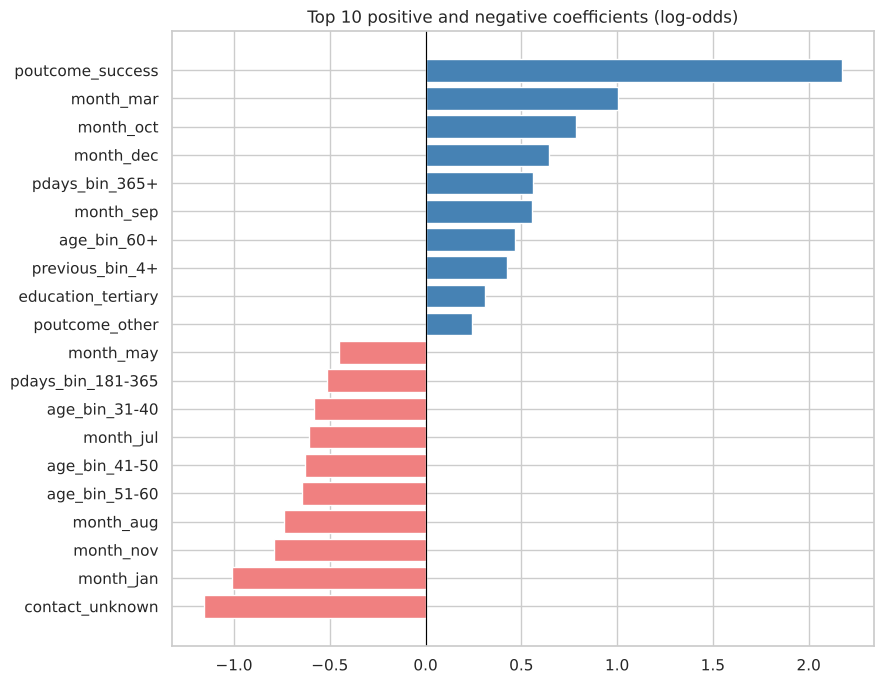

In [6]:
top = pd.concat([odds.head(10), odds.tail(10)])
plt.figure(figsize=(9, 7))
plt.barh(top['feature'], top['coef'], color=np.where(top['coef'] > 0, 'steelblue', 'lightcoral'))
plt.axvline(0, color='black', lw=0.8)
plt.gca().invert_yaxis()
plt.title('Top 10 positive and negative coefficients (log-odds)')
plt.tight_layout(); plt.show()

In [7]:
for f in ['poutcome_success', 'housing', 'contact_unknown', 'campaign']:
    r = odds.set_index('feature').loc[f, 'odds_ratio']
    print(f'{f:18s} odds ratio {r:.2f}')

poutcome_success   odds ratio 8.80
housing            odds ratio 0.65
contact_unknown    odds ratio 0.31
campaign           odds ratio 0.84


Reading the odds ratios (holding everything else equal):

- **poutcome = success**: odds of subscribing are **8.8×** higher than after a previous failure.
- **Housing loan**: odds × **0.65** (35% lower). **Personal loan**: × 0.74.
- **Contact channel "unknown"**: odds × **0.31**, the strongest negative effect.
- **campaign**: each extra standard deviation of (log) calls multiplies the odds by **0.84**, so repeated calls work against the bank.
- **Month**: March (× 2.73), October (× 2.19), December (× 1.91) and September (× 1.74) beat April; May (× 0.63) is worse.
- **Age 60+**: × 1.60 compared with 18–25, while the 31–60 groups sit around × 0.52–0.56: the U-shape from the EDA.

These match the EDA, which is a good sign the model learned real patterns.

In [8]:
import os
os.makedirs('../results', exist_ok=True)
pd.DataFrame({'y_true': y_test.values, 'logistic_regression': proba_lr}).to_csv('../results/test_probas.csv', index=False)
odds.round(4).to_csv('../results/lr_odds_ratios.csv', index=False)